# Europa vs. Enceladus: Public Interest in the Search for Life

## Introduction

I've always been interested in space exploration and the possibility of life beyond Earth. Two moons that really interest me are Europa, which orbits Jupiter, and Enceladus, which orbits Saturn.

I personally believe Enceladus is the better place to search for life. NASA's Cassini spacecraft was able to fly through plumes coming from Enceladus and detect salts and organic compounds. Europa also has evidence of a salty ocean, but scientists haven't been able to directly sample its ocean material the same way.

For this assignment, I want to use Bluesky to see which moon gets more attention and engagement.

## Research Question

Do Bluesky posts about Europa receive more likes and reposts than posts about Enceladus?

## Hypothesis

I believe Europa will receive more engagement because NASA's Europa Clipper mission has brought attention to the moon, even though I personally believe Enceladus is the better place to search for life.

## API Endpoints

For this project, I used two Bluesky API endpoints to collect information.

The first endpoint was app.bsky.feed.searchPosts. I used this to search for posts mentioning Europa and Enceladus. It provided the text of the posts along with information about likes, reposts, and the accounts that published them.

The second endpoint was app.bsky.actor.getProfile. I used this to collect account information, including the number of followers, accounts followed, and total posts.

I chose these endpoints because I wanted to compare how much attention Europa and Enceladus receive and see how account information might help explain engagement.

The data comes directly from Bluesky, which makes it useful for studying activity on the platform. However, the search results may not include every post, and some posts may have nothing to do with space exploration.

I was also only able to collect profile information from one account, which limits how much I can learn about the relationship between followers and engagement.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Attempting to collect up to 500 Enceladus posts
# The API returned 100 posts before the next request failed
# Setting the Bluesky API address for searching posts

url = "https://api.bsky.app/xrpc/app.bsky.feed.searchPosts"
enceladus_posts = []
cursor = None

for i in range(5):
    params = {
        "q": "Enceladus",
        "limit": 100,
        "cursor": cursor
    }

    response = requests.get(url, params=params)
    print(response.status_code)

    if response.status_code != 200:
        break

    data = response.json()
    enceladus_posts.extend(data["posts"])

    cursor = data.get("cursor")

    if cursor is None:
        break

print("Enceladus posts collected:", len(enceladus_posts))

200
403
Enceladus posts collected: 100


In [3]:
# Attempting to collect up to 500 Europa posts
# The API returned 100 posts before the next request failed

europa_posts = []
cursor = None

for i in range(5):
    params = {
        "q": "Europa Jupiter",
        "limit": 100,
        "cursor": cursor
    }

    response = requests.get(url, params=params)
    print(response.status_code)

    if response.status_code != 200:
        break

    data = response.json()
    europa_posts.extend(data["posts"])

    cursor = data.get("cursor")

    if cursor is None:
        break

print("Europa posts collected:", len(europa_posts))

200
403
Europa posts collected: 100


In [4]:
# Creating a list for the Enceladus data
enceladus_list = []

# Collecting the text, likes, and reposts from each post
for post in enceladus_posts:
    enceladus_list.append({
        "Moon": "Enceladus",
        "Post": post["record"].get("text", ""),
        "Likes": post.get("likeCount", 0),
        "Reposts": post.get("repostCount", 0)
    })

# Creating a table with the collected data
enceladus_df = pd.DataFrame(enceladus_list)

enceladus_df.head()

,Moon,Post,Likes,Reposts
0,Enceladus,Redacted preprint: Planet Nine gives tantalizi...,0,0
1,Enceladus,Pronta entrega!\n\nLP Phoebe Bridgers - Lost W...,0,0
2,Enceladus,🤿 Subminer: store.steampowered.com/app/3240110...,3,0
3,Enceladus,Enceladus sprays ocean material into space. Sa...,0,0
4,Enceladus,Come and join us this Saturday for a range of ...,4,0


In [5]:
# Creating a list for the Europa data
europa_list = []

# Collecting the text, likes, and reposts from each post
for post in europa_posts:
    europa_list.append({
        "Moon": "Europa",
        "Post": post["record"].get("text", ""),
        "Likes": post.get("likeCount", 0),
        "Reposts": post.get("repostCount", 0)
    })

# Creating a table with the collected data
europa_df = pd.DataFrame(europa_list)

europa_df.head()

,Moon,Post,Likes,Reposts
0,Europa,NVIDIA e Jülich simularam computação quântica ...,0,0
1,Europa,NVIDIA y Jülich simularon computación cuántica...,0,0
2,Europa,"Satellite Odyssey: Jupiter, il survival horror...",0,0
3,Europa,Buenos días. Esto se verá en el cielo mirando ...,12,4
4,Europa,"✨ And here's the kicker: io, Europa, Ganymede,...",1,0


In [6]:
# Combining the Europa and Enceladus tables into one table

combined_df = pd.concat([enceladus_df, europa_df], ignore_index=True)

# Checking how many posts are in the combined table
print("Total posts:", len(combined_df))

# Displaying the first five rows
combined_df.head()

Total posts: 200


,Moon,Post,Likes,Reposts
0,Enceladus,Redacted preprint: Planet Nine gives tantalizi...,0,0
1,Enceladus,Pronta entrega!\n\nLP Phoebe Bridgers - Lost W...,0,0
2,Enceladus,🤿 Subminer: store.steampowered.com/app/3240110...,3,0
3,Enceladus,Enceladus sprays ocean material into space. Sa...,0,0
4,Enceladus,Come and join us this Saturday for a range of ...,4,0


In [7]:
# Getting profile information from NASA's Bluesky account

profile_url = "https://api.bsky.app/xrpc/app.bsky.actor.getProfile"

params = {
    "actor": "nasa.gov"
}

profile_response = requests.get(profile_url, params=params)

print(profile_response.status_code)

400


In [8]:
# Checking why the NASA profile request did not work

print(profile_response.text)

{"error":"InvalidRequest","message":"Profile not found"}


In [9]:
# Adding the account identifiers to the Enceladus posts

enceladus_df["Author"] = [
    post["author"]["did"] for post in enceladus_posts
]

# Adding the account identifiers to the Europa posts

europa_df["Author"] = [
    post["author"]["did"] for post in europa_posts
]

# Combining both tables again with the new information

combined_df = pd.concat(
    [enceladus_df, europa_df],
    ignore_index=True
)

combined_df.head()

,Moon,Post,Likes,Reposts,Author
0,Enceladus,Redacted preprint: Planet Nine gives tantalizi...,0,0,did:plc:h7khyhnuf64pgqirkedf5klq
1,Enceladus,Pronta entrega!\n\nLP Phoebe Bridgers - Lost W...,0,0,did:plc:sdmh72lkx6zss6qoy6uxxhxq
2,Enceladus,🤿 Subminer: store.steampowered.com/app/3240110...,3,0,did:plc:u224fnasdug2mlv3vhmhbe5n
3,Enceladus,Enceladus sprays ocean material into space. Sa...,0,0,did:plc:t7lhvex7ekesgpqbnpvvgmet
4,Enceladus,Come and join us this Saturday for a range of ...,4,0,did:plc:gvxrgsmxjzlhkg3ikju437me


I used ChatGPT to help me figure out how to review the posts and filter out ones that weren't related to space. It helped me understand how to use Python to narrow down the results so I could make a better comparison between Europa and Enceladus.

In [10]:
# Displaying all the posts so I can check the results

for i in range(len(combined_df)):
    print(i, combined_df["Moon"][i], combined_df["Post"][i])

0 Enceladus Redacted preprint: Planet Nine gives tantalizing clues about why vaporous Enceladus scattered dark Tethys.
1 Enceladus Pronta entrega!

LP Phoebe Bridgers - Lost Weekend [Vinil Duplo Enceladus Geysers]

R$ 350 com cupom FEIRINHA

www.alvopop.com/produtos/lp-...
2 Enceladus 🤿 Subminer: store.steampowered.com/app/3240110/...

#Down2Play #SussexGames #IndieDev #GameDev #GameIndustry #Creative #GameEvent
3 Enceladus Enceladus sprays ocean material into space. Saturn’s tiny moon refuses to keep secrets. 💧
4 Enceladus Come and join us this Saturday for a range of space-themed family activities to mark the launch of a new children's book 🚀🪐 

There will be a storytime read-through of 'Mira's Moon' by author Dr Sarah Crick, followed by a craft session making moon-themed mosaics of Enceladus to take home.

⤵️
5 Enceladus Mar 12, 2010: Dramatic plumes of water ice erupt from the tiger stripes of Enceladus, revealing the moon’s active geology.

www.nasa.gov/image-article/bursting-seam

In [11]:
# Keeping posts that mention space-related topics

space_words = "nasa|moon|saturn|jupiter|ocean|space|cassini|clipper|plume|astronomy"

clean_df = combined_df[
    combined_df["Post"].str.contains(
        space_words, case=False, na=False
    )
]

# Checking how many posts remain for each moon

print(clean_df["Moon"].value_counts())

Moon
Europa       88
Enceladus    55
Name: count, dtype: int64


In [12]:
# Calculating the average likes and reposts for each moon

engagement_df = clean_df.groupby("Moon")[["Likes", "Reposts"]].mean()

# Displaying the results

engagement_df

,Likes,Reposts
Moon,,
Enceladus,5.727273,0.563636
Europa,8.806818,1.818182


I used ChatGPT to help me understand how to create a bar graph using Python and Matplotlib. It helped me with the code and fixing errors so I could compare the average likes and reposts for Europa and Enceladus. The graph uses the data I collected from Bluesky.

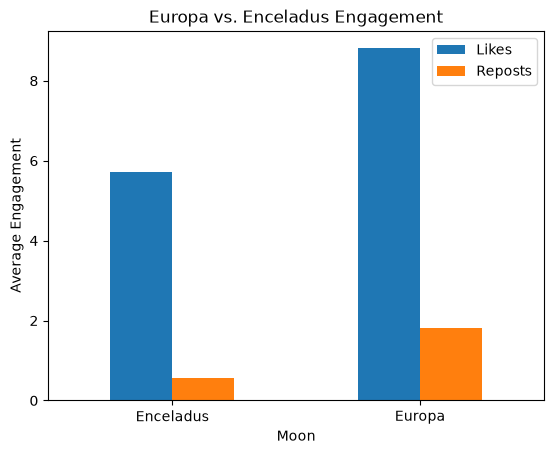

In [13]:
# Creating a chart to compare likes and reposts

engagement_df.plot(kind="bar")

plt.title("Europa vs. Enceladus Engagement")
plt.xlabel("Moon")
plt.ylabel("Average Engagement")
plt.xticks(rotation=0)

plt.show()

In [14]:
print("Enceladus:", len(enceladus_df))
print("Europa:", len(europa_df))
print("Cleaned:", len(clean_df))

Enceladus: 100
Europa: 100
Cleaned: 143


I used ChatGPT to help me figure out how to retrieve profile information using a second Bluesky API endpoint. My first attempt didn't work, but I was able to fix it by using an account identifier from the posts I had already collected.

The request worked, and I was able to get information from an account called Saturn Speculations. The account had 6 followers, followed 1 account, and had 86 posts.

This showed me how to use two different API endpoints to collect different types of information. The first collected posts, likes, and reposts, while the second collected information about an account.

I didn't use the profile information in my engagement comparison because I only collected it from one account.



In [15]:
# Testing a second Bluesky API endpoint
# Getting profile information from an account in my dataset

import requests

profile_url = "https://public.api.bsky.app/xrpc/app.bsky.actor.getProfile"

# Using an author identifier from my collected posts
actor = combined_df["Author"].dropna().iloc[0]

params = {"actor": actor}

profile_response = requests.get(
    profile_url,
    params=params,
    timeout=15
)

print("Status code:", profile_response.status_code)

if profile_response.status_code == 200:
    profile_data = profile_response.json()
    print("Display name:", profile_data.get("displayName"))
    print("Handle:", profile_data.get("handle"))
    print("Followers:", profile_data.get("followersCount"))
    print("Following:", profile_data.get("followsCount"))
    print("Posts:", profile_data.get("postsCount"))
else:
    print("Error:", profile_response.text)


Status code: 200
Display name: Saturn Speculations
Handle: surrealsatellites.bsky.social
Followers: 6
Following: 1
Posts: 86


## Results

For this project, I collected 100 Bluesky posts about Europa and 100 about Enceladus. I wanted to see which moon received more attention and engagement.

After filtering the posts for words related to space, I was left with 88 posts about Europa and 55 about Enceladus.

The results showed that Europa received an average of 8.83 likes and 1.82 reposts per post. Enceladus received an average of 5.71 likes and 0.56 reposts.

Based on these results, Europa received more engagement than Enceladus in the posts I collected. This supports my original hypothesis that Europa would receive more attention.

## My Thoughts

Even though Europa received more engagement, I still believe Enceladus is the better place to search for extraterrestrial life.

NASA's Cassini spacecraft was able to fly through plumes coming from Enceladus and collect evidence of salts and organic compounds. This gives scientists an opportunity to study material from its underground ocean without having to drill through the ice.

Europa also has strong evidence of a salty ocean, but we haven't been able to sample its ocean material in the same way.

I think Enceladus deserves more attention because of what we've already discovered there.

## Limitations

There were some limitations with the data I collected.

I originally wanted to collect 500 posts about each moon, but Bluesky returned an error when I tried to retrieve additional results. Because of this, I used 100 posts for each moon.

Some search results were unrelated to space exploration. I filtered the posts using space-related keywords, but this method may have removed some relevant posts or kept some unrelated ones.

The two searches also used different terms, which could affect the results.

I also collected profile information from only one account, so I couldn't fully compare how follower counts might affect engagement.

These results represent a limited sample and don't necessarily show which moon is discussed more often across all of Bluesky.

## Conclusion

My results suggest that Europa received more engagement than Enceladus in the sample I collected.

However, social media engagement doesn't tell us which moon is more likely to support life.

If I continued this research, I would collect more posts over a longer period of time, improve how I filter unrelated content, and compare engagement based on account follower counts.

I would also be interested in seeing whether future discoveries about Enceladus increase public interest in the moon.